# Eleições 2026 e a dinâmica da dívida pública — modelo e simulação estocástica (v2)

Gabriel Pires · [@gabrielp.pires](https://instagram.com/gabrielp.pires) · data-base 18/09/2026 · **revisão de 26/09/2026**

Notebook que reproduz **todos os números e gráficos** do relatório *Eleições 2026 e a dinâmica da dívida pública brasileira* (versão revisada).

**Estrutura**
1. Dados de partida, cenários e parâmetros
2. (Opcional) Atualização com o SGS e o Focus do BCB
3. Aritmética da dívida: primário estabilizador
4. Modelo semiestrutural anual (dívida, prêmio, câmbio, PIB, IPCA, Selic, juros)
5. Cenários determinísticos e validação contra o Focus
6. De onde vem a diferença A − B1 (Shapley)
7. Monte Carlo com os mesmos choques macro nos três cenários
8. A diferença entre os favoritos sob incerteza
9. Mistura ponderada pela eleição e decomposição da variância
10. Sensibilidade: parâmetros e custos não quantificados
11. O que um pregão implica
12. Calibração dos choques com os erros do Focus

> Os cenários são **condicionais**: traduzem os programas em trajetórias de primário com premissas explícitas. Altere as células da seção 1 para testar hipóteses próprias. Nada aqui é recomendação de voto ou de investimento.

### O que mudou em relação à versão de 18/09
| Item | Antes | Agora |
|---|---|---|
| Ponto de partida | 84,0% (hipótese) | 83,4% (Focus para dez/26), com incerteza de 1,5 p.p. |
| Referência sem nova política (P0) | −0,4 a −0,2% (≈ IFI) | primário esperado pelo Focus; validado contra a DBGG do Focus |
| Baseline | PIB 2028 = 2,0; câmbio 2029+ = 5,30 | valores do Focus (1,87; 5,36; 5,40) |
| B1 e C | níveis de primário | ajuste sobre P0 (mesmos p.p.) |
| Repasse cambial | sobre o nível do câmbio | sobre a variação |
| Juros nominais | proxy × 1,14 | coerentes com a equação da dívida |
| Choques | hipóteses (σ = 1,2; 0,7; 0,4) | erros do Focus 2003–2025 sem 2020–21 |
| Monte Carlo | semente diferente por cenário | mesmos choques macro nos três cenários |
| `mistura()` | sorteava uma trajetória por variável | preserva a trajetória inteira |
| Teste de execução | "igual para todos" (repetia a Beta de B1) | B1 com Beta(4; 6) + ponto de empate |
| Novas análises | — | Shapley, distribuição da diferença, variância, custos não quantificados, leitura do pregão |

In [1]:
import itertools, math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.color": "#E3E8EE", "axes.spines.top": False,
                     "axes.spines.right": False, "axes.axisbelow": True, "legend.frameon": False})
virg = FuncFormatter(lambda v, p: f"{v:g}".replace(".", ","))
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

## 1. Dados de partida, cenários e parâmetros

**Baseline (fontes):** DBGG de 82,5% do PIB em jul/26 (BCB; 82,56% no SGS 13762); Boletim Focus de 14/09/2026 (coleta até 11/09) para PIB, IPCA, Selic, câmbio, **primário e DBGG**; juro real implícito de 5,2% (IFI, RAF 113).

**Cenários (primário planejado, % do PIB):**
- **A — Continuidade (Lula):** arcabouço vigente + despesas contratadas; definido em nível, como as metas.
- **B1 — Ajuste integral (Flávio):** ajuste de 0,9 a 2,0 p.p. sobre P0 (≈2% do PIB; reportagem sobre a equipe, não consta do programa oficial). **Não desconta os cortes de tributos prometidos** (seção 10).
- **C — Ajuste declarado (Renan Santos):** 0,8 a 1,8 p.p. sobre P0 (≈R$ 1 tri em 2027–2031).
- **P0 — Referência:** primário esperado pelo Focus (sem nova política).

`exec_ab` são os parâmetros da Beta que sorteia a fração `u` do ajuste efetivamente entregue.

In [2]:
import itertools, math
import numpy as np
import pandas as pd

ANOS = np.arange(2027, 2032)
T = len(ANOS)

# ---------------------------------------------------------------------------
# 1) Baseline exógeno: Boletim Focus de 14/09/2026 (coleta até 11/09) e IFI
# ---------------------------------------------------------------------------
BASE = dict(
    d0=83.4,         # DBGG esperada p/ dez/2026 (Focus 14/09/2026); jul/26 = 82,56% (BCB, SGS 13762)
    d_2025=78.64,    # DBGG dez/2025 (BCB, SGS 13762)
    pb_2026=-0.45,   # primário 2026 (Focus 14/09/2026)
    g_2026=1.89,     # Focus 14/09/2026
    ipca_2026=4.90,  # Focus 14/09/2026
    r_impl=5.2,      # juro real implícito da DBGG (IFI, RAF 113)
    g=np.array([1.45, 1.87, 2.00, 2.00, 2.00]),       # Focus 2027-30; 2031 = 2030
    ipca=np.array([4.30, 3.80, 3.50, 3.50, 3.50]),    # Focus 2027-30; 2031 = 2030
    selic=np.array([12.0, 10.5, 10.0, 10.0, 10.0]),   # Focus 2027-30; 2031 = 2030
    cambio=np.array([5.275, 5.30, 5.363, 5.40, 5.40]),# Focus 2027-30; 2031 = 2030
)

# Trajetória de referência (sem nova política): primário esperado pelo Focus; 2031 = 2030
P0 = np.array([-0.40, -0.22, -0.15, -0.025, -0.025])

# Focus 14/09/2026 para validação
FOCUS_DBGG = {2026: 83.40, 2027: 87.21, 2028: 90.33, 2029: 92.85, 2030: 95.06}
FOCUS_NOMINAL = {2027: 8.50, 2028: 7.89, 2029: 7.39, 2030: 7.23}   # déficit nominal (NFSP), % PIB

# ---------------------------------------------------------------------------
# 2) Cenários (primário planejado, % PIB) e execução u ~ Beta(a, b)
#    A é definido em nível (metas do arcabouço); B1 e C como ajuste sobre P0,
#    porque é assim que foram anunciados (≈2% do PIB; ≈R$ 1 tri em 5 anos).
# ---------------------------------------------------------------------------
AJ_B1 = np.array([0.9, 1.6, 1.9, 1.9, 2.0])
AJ_C = np.array([0.8, 1.3, 1.6, 1.8, 1.8])
CENARIOS = {
    "A":  dict(nome="Continuidade (Lula)", pb=np.array([0.0, 0.25, 0.50, 0.75, 0.75]), exec_ab=(7.0, 3.0), cor="#C0392B"),
    "B1": dict(nome="Ajuste integral (Flávio)", pb=P0 + AJ_B1, exec_ab=(5.5, 4.5), cor="#1F4E79"),
    "C":  dict(nome="Ajuste declarado (Renan Santos)", pb=P0 + AJ_C, exec_ab=(4.0, 6.0), cor="#2E8B57"),
}

# ---------------------------------------------------------------------------
# 3) Parâmetros estruturais (calibrados)
# ---------------------------------------------------------------------------
PARAM = dict(mu=0.5, kappa=0.30, delta=0.04, d_conv=90.0, phi=0.3, eps_fx=6.0, pt_fx=0.08,
             pt_g=0.25, taylor_pi=1.5, taylor_g=0.5, lam=0.5, sens_pb_g=0.2)

# Choques: erros de previsão do Focus (set/t-1 -> t), 2003-2025 sem 2020-21 (pandemia; n = 21),
# já descontadas a regra de Taylor (juro) e a parte cíclica (primário) que o modelo gera.
CHOQUES = dict(sd_g=2.15, rho_g=0.13, sd_r=1.94, rho_r=-0.22, corr_gr=-0.27,
               sd_pb=1.15, rho_pb=0.26, sd_d0=1.5)
CHOQUES_V1 = dict(sd_g=1.2, rho_g=0.3, sd_r=0.7, rho_r=0.5, corr_gr=-0.3, sd_pb=0.4, rho_pb=0.0, sd_d0=0.6)


def _ar1(z, sd, rho):
    """Transforma inovações N(0,1) (N x T) num AR(1) estacionário de desvio-padrão sd."""
    x = np.zeros_like(z)
    x[:, 0] = sd * z[:, 0]
    s_inn = sd * np.sqrt(1 - rho ** 2)
    for t in range(1, z.shape[1]):
        x[:, t] = rho * x[:, t - 1] + s_inn * z[:, t]
    return x


def sortear_choques(N, choques=None, seed=2026):
    """Choques macro comuns a todos os cenários (números aleatórios comuns)."""
    c = choques or CHOQUES
    rng = np.random.default_rng(seed)
    L = np.linalg.cholesky(np.array([[1, c["corr_gr"]], [c["corr_gr"], 1]]))
    z = rng.standard_normal((N, T, 2)) @ L.T
    return dict(eg=_ar1(z[:, :, 0], c["sd_g"], c["rho_g"]),
                er=_ar1(z[:, :, 1], c["sd_r"], c["rho_r"]),
                epb=_ar1(rng.standard_normal((N, T)), c["sd_pb"], c.get("rho_pb", 0.0)),
                ed0=c["sd_d0"] * rng.standard_normal(N))


def simular(pb_plan, N=1, param=None, base=None, sh=None, u=None, p0=None, dref="auto"):
    """Simula N trajetórias (sh=None -> determinístico). Retorna dict de arrays N x T."""
    p = dict(PARAM, **(param or {}))
    b = dict(BASE, **(base or {}))
    p0 = P0 if p0 is None else np.asarray(p0, float)
    pb_plan = np.asarray(pb_plan, dtype=float)
    u = np.ones(N) if u is None else np.asarray(u, float).reshape(N)
    z = np.zeros((N, T))
    eg, er, epb = (z, z, z) if sh is None else (sh["eg"][:N], sh["er"][:N], sh["epb"][:N])
    d_ini = np.full(N, b["d0"], float) + (0 if sh is None else sh["ed0"][:N])

    if isinstance(dref, str) and dref == "auto":
        dref = simular(p0, N=1, param=param, base=base, p0=p0, dref=None)["d"][0]

    pb_pol = p0 + u[:, None] * (pb_plan - p0)
    out = {v: np.zeros((N, T)) for v in ["d", "pb", "pb_pol", "g", "ipca", "selic", "cambio", "r", "premio", "juros", "nominal"]}
    d_prev = d_ini.copy(); dref_prev = b["d0"]
    pb_prev = np.full(N, b["pb_2026"]); pb0_prev = b["pb_2026"]
    rr_prev = np.zeros(N); rimp_dev = np.zeros(N); fx_prev = np.zeros(N)

    for t in range(T):
        prem = -p["kappa"] * (pb_pol[:, t] - p0[t])
        if dref is not None:
            conv = 1 + np.maximum(0, d_prev - p["d_conv"]) / 10
            prem = prem + p["delta"] * conv * (d_prev - dref_prev)
        fx = p["eps_fx"] * prem                                   # desvio do NÍVEL do câmbio (%)
        gF = -p["mu"] * ((pb_pol[:, t] - pb_prev) - (p0[t] - pb0_prev))
        g = b["g"][t] + gF - p["phi"] * rr_prev + eg[:, t]
        dg = g - b["g"][t]
        pi = b["ipca"][t] + p["pt_fx"] * (fx - fx_prev) + p["pt_g"] * dg   # repasse sobre a VARIAÇÃO
        dpi = pi - b["ipca"][t]
        selic = b["selic"][t] + prem + p["taylor_pi"] * dpi + p["taylor_g"] * dg + er[:, t]
        rr = (selic - b["selic"][t]) - dpi                         # desvio do juro real de mercado
        rimp_dev = rimp_dev + p["lam"] * (rr - rimp_dev)
        r = b["r_impl"] + rimp_dev
        pb = pb_pol[:, t] + p["sens_pb_g"] * dg + epb[:, t]
        d = d_prev * (1 + r / 100) / (1 + g / 100) - pb
        i_nom = ((1 + r / 100) * (1 + pi / 100) - 1) * 100
        juros = i_nom * d_prev / 100 / ((1 + g / 100) * (1 + pi / 100))   # coerente com a equação da dívida
        for name, val in [("d", d), ("pb", pb), ("pb_pol", pb_pol[:, t]), ("g", g), ("ipca", pi), ("selic", selic),
                          ("cambio", b["cambio"][t] * (1 + fx / 100)), ("r", r), ("premio", prem),
                          ("juros", juros), ("nominal", juros - pb)]:
            out[name][:, t] = val
        pb0_prev = p0[t]; pb_prev = pb_pol[:, t]; rr_prev = rr; d_prev = d; fx_prev = fx
        if dref is not None:
            dref_prev = dref[t]
    return out


def deterministico(param=None, base=None):
    linhas = []
    for c, cfg in CENARIOS.items():
        s = simular(cfg["pb"], param=param, base=base)
        for t, ano in enumerate(ANOS):
            linhas.append(dict(cenario=c, nome=cfg["nome"], ano=ano, **{v: s[v][0, t] for v in s}))
    return pd.DataFrame(linhas)


def sortear_u(N, exec_ab, seed):
    a, b = exec_ab
    return np.random.default_rng(seed).beta(a, b, N)


def monte_carlo(N=20000, seed=2026, choques=None, exec_ab=None, param=None, base=None, planos=None):
    """Monte Carlo com os MESMOS choques macro em todos os cenários; u sorteado por cenário.
    exec_ab: dict {cenário: (a, b)} para sobrepor a execução; (1e9, 1) ~ execução integral."""
    sh = sortear_choques(N, choques, seed)
    res = {}
    for i, (c, cfg) in enumerate(CENARIOS.items()):
        ab = (exec_ab or {}).get(c, cfg["exec_ab"])
        u = sortear_u(N, ab, seed + 101 + i)
        plano = (planos or {}).get(c, cfg["pb"])
        res[c] = simular(plano, N=N, sh=sh, u=u, param=param, base=base)
        res[c]["u"] = u
    return res


INTEGRAL = {c: (1e9, 1.0) for c in CENARIOS}


def mistura(res, pesos, N=20000, seed=7):
    """Combina trajetórias inteiras (todas as variáveis da mesma trajetória) segundo pesos eleitorais."""
    rng = np.random.default_rng(seed)
    keys = list(pesos)
    idx = rng.choice(len(keys), size=N, p=np.array([pesos[k] for k in keys]))
    pick = rng.integers(0, res[keys[0]]["d"].shape[0], N)
    out = {}
    for v in ["d", "pb", "g", "ipca", "selic", "r"]:
        arr = np.zeros((N, T))
        for j, k in enumerate(keys):
            m = idx == j
            arr[m] = res[k][v][pick[m]]
        out[v] = arr
    out["cand"] = np.array(keys)[idx]
    return out


def estatisticas(d, limiares=(90, 95)):
    x = d[:, -1]
    s = dict(p5=np.percentile(x, 5), p25=np.percentile(x, 25), mediana=np.median(x),
             p75=np.percentile(x, 75), p95=np.percentile(x, 95),
             prob_cai=np.mean(x <= d[:, 0]) * 100)
    for L in limiares:
        s[f"prob_>{L}"] = np.mean(x > L) * 100
    return s


def pb_estabilizador(d, r, g):
    return d * (r - g) / (100 + g)


# ---------------------------------------------------------------------------
# Decomposições
# ---------------------------------------------------------------------------
CANAIS = {"premio": dict(kappa=0.0, delta=0.0), "crescimento": dict(mu=0.0, phi=0.0)}


def shapley_gap(a="A", b="B1"):
    """Shapley da diferença de DBGG em 2031 (a - b), determinístico, execução integral."""
    def gap(ativos):
        p = {}
        for c, off in CANAIS.items():
            if c not in ativos:
                p.update(off)
        return simular(CENARIOS[a]["pb"], param=p)["d"][0, -1] - simular(CENARIOS[b]["pb"], param=p)["d"][0, -1]
    nomes = list(CANAIS)
    phi = {"primario": gap(set())}
    for c in nomes:
        outros = [o for o in nomes if o != c]
        v = 0.0
        for k in range(len(outros) + 1):
            for S in itertools.combinations(outros, k):
                w = math.factorial(k) * math.factorial(len(nomes) - k - 1) / math.factorial(len(nomes))
                v += w * (gap(set(S) | {c}) - gap(set(S)))
        phi[c] = v
    phi["total"] = gap(set(nomes))
    return phi


def decompor_variancia(res_ex, res_u1, pesos):
    """Lei da variância total para a DBGG de 2031 na mistura eleitoral."""
    ks = list(pesos); w = np.array([pesos[k] for k in ks])
    m = np.array([res_ex[k]["d"][:, -1].mean() for k in ks])
    v_ex = np.array([res_ex[k]["d"][:, -1].var() for k in ks])
    v_u1 = np.array([res_u1[k]["d"][:, -1].var() for k in ks])
    eleicao = float(np.sum(w * (m - np.sum(w * m)) ** 2))
    macro = float(np.sum(w * v_u1)); execucao = float(np.sum(w * (v_ex - v_u1)))
    tot = eleicao + macro + execucao
    return dict(macro=macro / tot, execucao=execucao / tot, eleicao=eleicao / tot, total_var=tot)

## 2. (Opcional) Atualização com o SGS e o Focus

APIs públicas do BCB. SGS: `13762` DBGG (% PIB), `432` meta Selic, `5793` NFSP primário 12m, `7326` PIB real, `13522` IPCA 12m, `4189` Selic média mensal.
Focus (Olinda): `ExpectativasMercadoAnuais`. Com `ATUALIZAR = True`, o ponto de partida `BASE["d0"]` passa a ser a mediana mais recente do Focus para a DBGG de dezembro.

In [3]:
ATUALIZAR = False
OLINDA = "https://olinda.bcb.gov.br/olinda/servico/Expectativas/versao/v1/odata/ExpectativasMercadoAnuais"

def baixar_sgs(codigo, inicio="01/01/2000"):
    import requests
    url = f"https://api.bcb.gov.br/dados/serie/bcdata.sgs.{codigo}/dados?formato=json&dataInicial={inicio}"
    r = requests.get(url, timeout=30); r.raise_for_status()
    df = pd.DataFrame(r.json())
    df["data"] = pd.to_datetime(df["data"], dayfirst=True)
    df["valor"] = pd.to_numeric(df["valor"])
    return df.set_index("data")["valor"]

def focus(indicador, referencia, data_ini, data_fim):
    import requests
    from urllib.parse import quote
    f = (f"Indicador eq '{indicador}' and DataReferencia eq '{referencia}' and Data ge '{data_ini}' "
         f"and Data le '{data_fim}' and baseCalculo eq 0")
    url = OLINDA + "?$format=json&$top=100&$select=Indicador,Data,DataReferencia,Mediana&$filter=" + quote(f, safe="'")
    r = requests.get(url, timeout=60); r.raise_for_status()
    return pd.DataFrame(r.json()["value"])

if ATUALIZAR:
    try:
        import datetime as dt
        hoje = dt.date.today(); ini = (hoje - dt.timedelta(days=10)).isoformat()
        df = focus("Dívida bruta do governo geral", str(hoje.year), ini, hoje.isoformat())
        BASE["d0"] = float(df.sort_values("Data")["Mediana"].iloc[-1])
        print(f"d0 atualizado pelo Focus: {BASE['d0']}%")
    except Exception as e:
        print("Não foi possível acessar o BCB; mantendo valores do relatório.", e)
else:
    print(f"Usando valores do relatório: d0 = {BASE['d0']}%")

Usando valores do relatório: d0 = 83.4%


## 3. Aritmética da dívida

$d_t = d_{t-1}\,\frac{1+r_t}{1+g_t} - pb_t \quad\Rightarrow\quad pb^* = d\,\frac{r-g}{1+g}$

Com $d \approx 85$: $\partial pb^*/\partial r = d/(1+g) \approx 0{,}84$ e $\partial pb^*/\partial g = -d(1+r)/(1+g)^2 \approx -0{,}87$.

In [4]:
rs = np.array([3.5, 4.0, 4.5, 5.0, 5.2, 5.5, 6.0, 6.5]); gs = np.arange(0.5, 4.01, 0.5)
M = pd.DataFrame([[pb_estabilizador(85, r, g) for g in gs] for r in rs], index=rs, columns=gs)
M.index.name = "r \\ g"
print("Primário estabilizador com d = 85% do PIB:")
display(M.round(1))
print(f"Caso de referência (r = 5,2; g = 1,5): {pb_estabilizador(85, 5.2, 1.5):.2f}% do PIB")
print(f"dpb*/dr = {85 / 1.015 / 100:.2f}   dpb*/dg = {-85 * 1.052 / 1.015**2 / 100:.2f}")

Primário estabilizador com d = 85% do PIB:


,0.50,1.00,1.50,2.00,2.50,3.00,3.50,4.00
r \ g,,,,,,,,
3.50,2.50,2.10,1.70,1.20,0.80,0.40,0.00,-0.40
4.00,3.00,2.50,2.10,1.70,1.20,0.80,0.40,0.00
4.50,3.40,2.90,2.50,2.10,1.70,1.20,0.80,0.40
5.00,3.80,3.40,2.90,2.50,2.10,1.70,1.20,0.80
5.20,4.00,3.50,3.10,2.70,2.20,1.80,1.40,1.00
5.50,4.20,3.80,3.30,2.90,2.50,2.10,1.60,1.20
6.00,4.70,4.20,3.80,3.30,2.90,2.50,2.10,1.60
6.50,5.10,4.60,4.20,3.80,3.30,2.90,2.50,2.00


Caso de referência (r = 5,2; g = 1,5): 3.10% do PIB
dpb*/dr = 0.84   dpb*/dg = -0.87


## 4. Modelo semiestrutural anual

Blocos (desvios em relação ao baseline Focus + referência P0):
- **Prêmio:** $\Delta\rho = -\kappa(pb^{pol}-pb^0) + \delta\,c(d_{-1})\,(d_{-1}-d^0_{-1})$, convexo acima de 90%
- **Câmbio (nível):** $\Delta e\,(\%) = \varepsilon\,\Delta\rho$
- **PIB:** $g = g^b - \mu(\Delta pb^{pol}-\Delta pb^0) - \phi\,\Delta rr_{-1} + \epsilon_g$
- **IPCA:** $\pi = \pi^b + \theta_e\,(\Delta e - \Delta e_{-1}) + \theta_g (g-g^b)$ — repasse sobre a **variação** do câmbio
- **Selic:** $i = i^b + \Delta\rho + 1{,}5(\pi-\pi^b) + 0{,}5(g-g^b) + \epsilon_r$
- **Custo da dívida:** $\Delta r = \Delta r_{-1} + \lambda(\Delta rr - \Delta r_{-1})$
- **Primário efetivo:** $pb = pb^{pol} + 0{,}2(g-g^b) + \epsilon_{pb}$, $pb^{pol} = pb^0 + u\,(pb^{plano}-pb^0)$
- **Juros:** $j = d_{-1}[(1+r)(1+\pi)-1]/[(1+g)(1+\pi)]$, coerente com a equação da dívida (a v1 usava um fator de 1,14)

A função `simular` está na célula da seção 1. Os choques macro são sorteados uma vez (`sortear_choques`) e aplicados igualmente aos três cenários.

## 5. Cenários determinísticos (execução integral, sem choques) e validação contra o Focus

In [5]:
df = deterministico()
ref = simular(P0)
tab = df.pivot(index="ano", columns="cenario", values="d")
tab["P0"] = ref["d"][0]
tab["Focus"] = [FOCUS_DBGG.get(a, np.nan) for a in tab.index]
print("DBGG (% do PIB):"); display(tab.round(1))
print(f"Erro máximo de P0 contra a DBGG do Focus até 2030: {np.nanmax(np.abs(tab['P0'] - tab['Focus'])):.2f} p.p.")

cols = ["d", "pb", "g", "ipca", "selic", "cambio", "juros", "nominal", "r", "premio"]
display(df[df.ano.isin([2027, 2030, 2031])].set_index(["cenario", "ano"])[cols].round(2))

DBGG (% do PIB):


cenario,A,B1,C,P0,Focus
ano,,,,,
2027,86.60,86.20,86.30,86.90,87.20
2028,89.00,87.40,87.80,89.90,90.30
2029,91.20,87.80,88.70,92.90,92.80
2030,93.00,88.00,89.10,95.90,95.10
2031,94.80,87.90,89.30,98.90,NaN


Erro máximo de P0 contra a DBGG do Focus até 2030: 0.79 p.p.


d    pb    g  ipca  selic  cambio  juros  nominal    r  \
cenario ano                                                               
A       2027 86.58 -0.04 1.25  4.19  11.62    5.24   7.48     7.52 5.06   
        2030 93.01  0.75 2.02  3.47   9.65    5.30   7.41     6.65 4.94   
        2031 94.80  0.77 2.09  3.49   9.65    5.28   7.54     6.77 4.90   
B1      2027 86.20  0.41 1.00  4.06  11.14    5.19   7.26     6.85 4.89   
        2030 87.96  1.92 2.20  3.50   9.33    5.15   6.84     4.92 4.57   
        2031 87.95  2.01 2.15  3.47   9.11    5.10   6.73     4.72 4.46   
C       2027 86.28  0.32 1.05  4.08  11.24    5.20   7.30     6.98 4.93   
        2030 89.05  1.79 2.08  3.45   9.26    5.17   6.90     5.10 4.60   
        2031 89.28  1.82 2.21  3.50   9.30    5.14   6.91     5.10 4.55   

              premio  
cenario ano           
A       2027   -0.12  
        2030   -0.31  
        2031   -0.38  
B1      2027   -0.27  
        2030   -0.77  
        2031   -0.92  
C       2027   -0.24  
        2030   -0.71  
        2031   -0.81

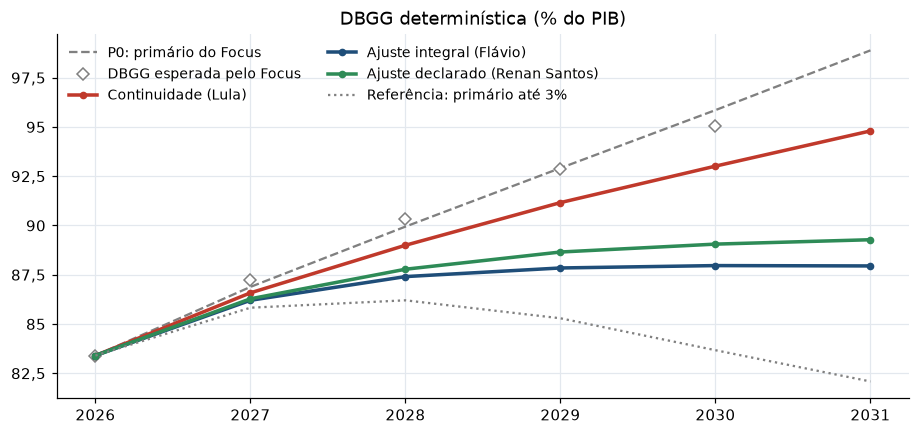

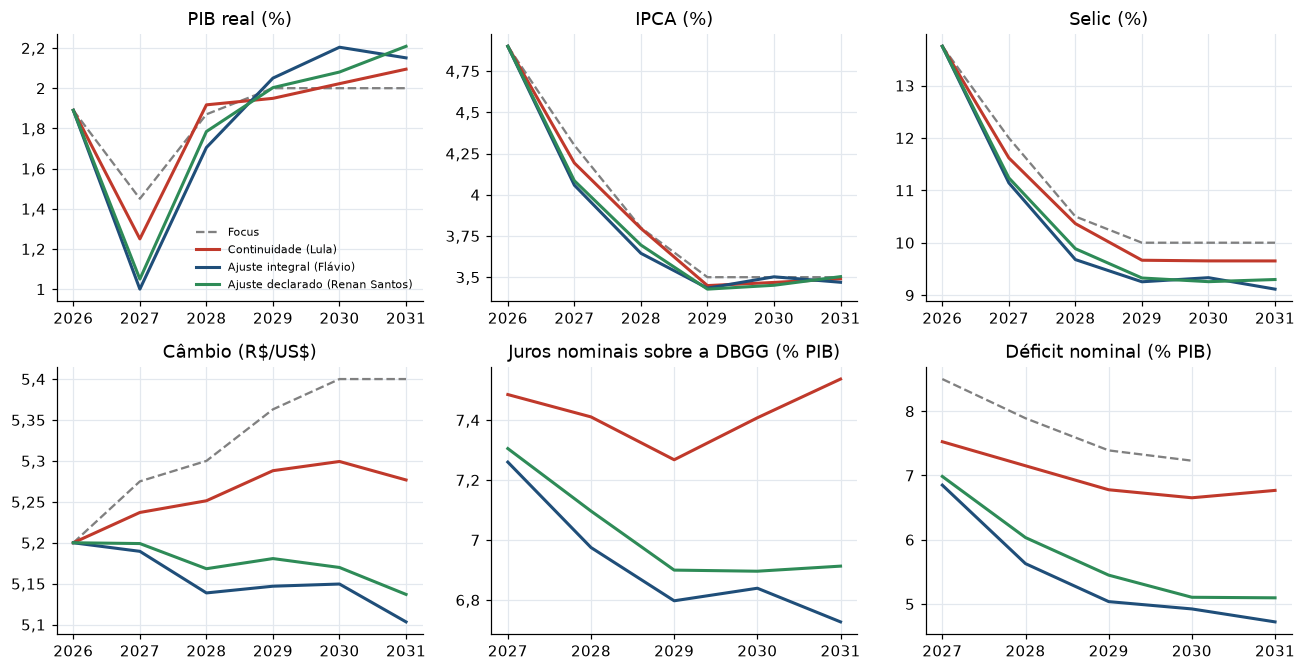

In [6]:
anos_ext = np.r_[2026, ANOS]
fig, ax = plt.subplots(figsize=(10, 4.3))
ax.plot(anos_ext, np.r_[BASE["d0"], ref["d"][0]], color="grey", ls="--", label="P0: primário do Focus")
ax.plot(list(FOCUS_DBGG), list(FOCUS_DBGG.values()), "D", mfc="white", mec="grey", label="DBGG esperada pelo Focus")
for c, cfg in CENARIOS.items():
    ax.plot(anos_ext, np.r_[BASE["d0"], tab[c]], color=cfg["cor"], lw=2.3, marker="o", ms=4, label=cfg["nome"])
est = simular([1.0, 2.0, 3.0, 3.0, 3.0])["d"][0]
ax.plot(anos_ext, np.r_[BASE["d0"], est], color="grey", ls=":", label="Referência: primário até 3%")
ax.set_title("DBGG determinística (% do PIB)"); ax.legend(ncol=2, fontsize=9); ax.yaxis.set_major_formatter(virg)
plt.show()

spec = [("g", "PIB real (%)", BASE["g_2026"], BASE["g"]), ("ipca", "IPCA (%)", BASE["ipca_2026"], BASE["ipca"]),
        ("selic", "Selic (%)", 13.75, BASE["selic"]), ("cambio", "Câmbio (R$/US$)", 5.20, BASE["cambio"]),
        ("juros", "Juros nominais sobre a DBGG (% PIB)", None, None), ("nominal", "Déficit nominal (% PIB)", None, None)]
fig, axs = plt.subplots(2, 3, figsize=(12, 6.2))
for ax, (v, t, v26, b) in zip(axs.flat, spec):
    if b is not None:
        ax.plot(anos_ext, np.r_[v26, b], color="grey", ls="--", label="Focus")
        for c, cfg in CENARIOS.items():
            ax.plot(anos_ext, np.r_[v26, df[df.cenario == c][v].values], color=cfg["cor"], lw=2, label=cfg["nome"])
    else:
        if v == "nominal":
            ax.plot(list(FOCUS_NOMINAL), list(FOCUS_NOMINAL.values()), color="grey", ls="--", label="Focus (NFSP)")
        for c, cfg in CENARIOS.items():
            ax.plot(ANOS, df[df.cenario == c][v].values, color=cfg["cor"], lw=2, label=cfg["nome"])
    ax.set_title(t.replace("$", r"\$")); ax.yaxis.set_major_formatter(virg)
axs[0, 0].legend(fontsize=7.5); plt.tight_layout(); plt.show()

## 6. De onde vem a diferença A − B1 (Shapley)

Desligamos os canais do modelo — prêmio ($\kappa=\delta=0$) e crescimento ($\mu=\phi=0$) — e calculamos o valor de Shapley de cada canal sobre as combinações. Sem canais, sobra o efeito direto do primário.

In [7]:
sh = shapley_gap()
tot = sh["total"]
print(f"Diferença A − B1 em 2031: {tot:.2f} p.p.")
for k in ["primario", "premio", "crescimento"]:
    print(f"  {k:12s} {sh[k]:+.2f} p.p. ({sh[k] / tot:.0%})")
print(f"Soma da diferença de primário planejado (B1 − A), 2027–31: {(CENARIOS['B1']['pb'] - CENARIOS['A']['pb']).sum():.2f} p.p.")

Diferença A − B1 em 2031: 6.85 p.p.
  primario     +5.52 p.p. (81%)
  premio       +1.54 p.p. (23%)
  crescimento  -0.21 p.p. (-3%)
Soma da diferença de primário planejado (B1 − A), 2027–31: 5.23 p.p.


## 7. Monte Carlo

Choques calibrados na seção 12: $\epsilon_g$ AR(1) ($\sigma=2{,}15$; $\rho=0{,}13$), $\epsilon_r$ AR(1) ($\sigma=1{,}94$; $\rho=-0{,}22$), $corr(g,r)=-0{,}27$; $\epsilon_{pb}$ AR(1) ($\sigma=1{,}15$; $\rho=0{,}26$); $d_{2026}\sim N(83{,}4;\,1{,}5)$; $u\sim Beta(a,b)$ por trajetória.
**Os três cenários recebem os mesmos choques macro** (números aleatórios comuns).

Regimes: **execução integral** (u = 1), **base** (Beta por cenário) e **B1 com execução baixa** (Beta(4; 6), média 0,40).

In [8]:
N = 20000
res_u1 = monte_carlo(N, exec_ab=INTEGRAL)
res_ex = monte_carlo(N)
res_b1low = monte_carlo(N, exec_ab={"B1": (4.0, 6.0)})

linhas = []
for lab, R in [("Execução integral", res_u1), ("Com execução (base)", res_ex), ("B1 com execução baixa", res_b1low)]:
    for c in CENARIOS:
        if lab == "B1 com execução baixa" and c != "B1":
            continue
        linhas.append(dict(regime=lab, cenario=c, **estatisticas(R[c]["d"]), dp=R[c]["d"][:, -1].std()))
tab_mc = pd.DataFrame(linhas).set_index(["cenario", "regime"])
display(tab_mc.round(1))
print("Fração média executada (base):", {c: round(res_ex[c]["u"].mean(), 2) for c in CENARIOS})

,,p5,p25,mediana,p75,p95,prob_cai,prob_>90,prob_>95,dp
cenario,regime,,,,,,,,,
A,Execução integral,84.10,90.30,94.90,99.80,107.30,7.00,76.50,49.40,7.10
B1,Execução integral,77.50,83.50,88.00,92.70,99.70,36.90,38.70,15.40,6.80
C,Execução integral,78.80,84.80,89.30,94.00,101.20,29.00,46.10,20.70,6.80
A,Com execução (base),85.30,91.50,96.10,101.10,108.80,4.70,81.70,56.60,7.20
B1,Com execução (base),81.90,88.20,92.90,97.80,105.50,13.30,66.00,38.60,7.20
C,Com execução (base),84.10,90.40,95.10,100.00,107.80,7.10,77.00,50.60,7.20
B1,B1 com execução baixa,83.40,89.90,94.60,99.50,107.30,8.50,74.30,47.80,7.30


Fração média executada (base): {'A': np.float64(0.7), 'B1': np.float64(0.55), 'C': np.float64(0.4)}


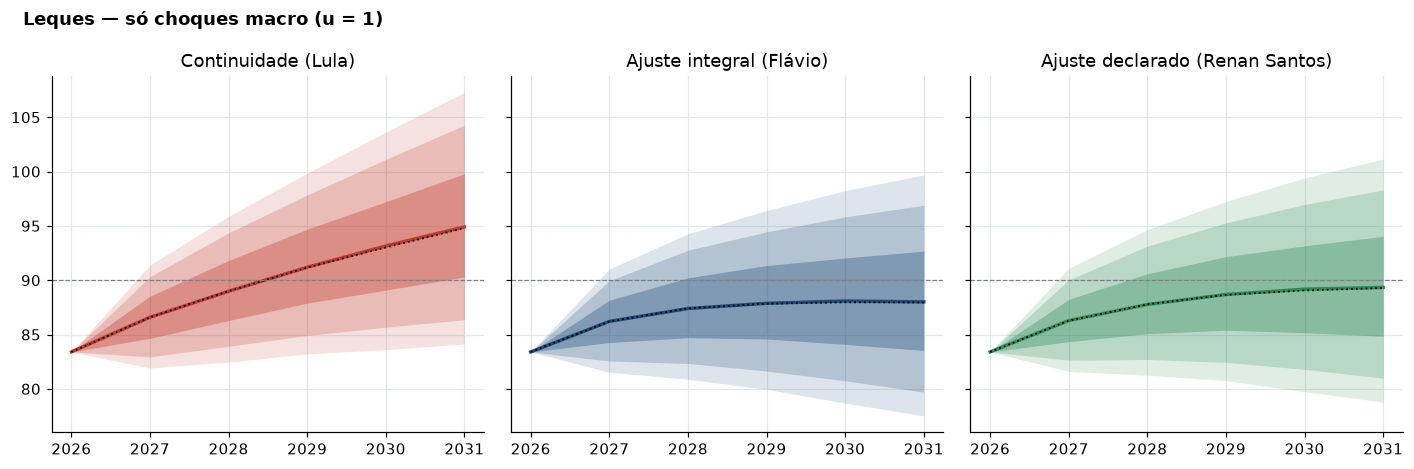

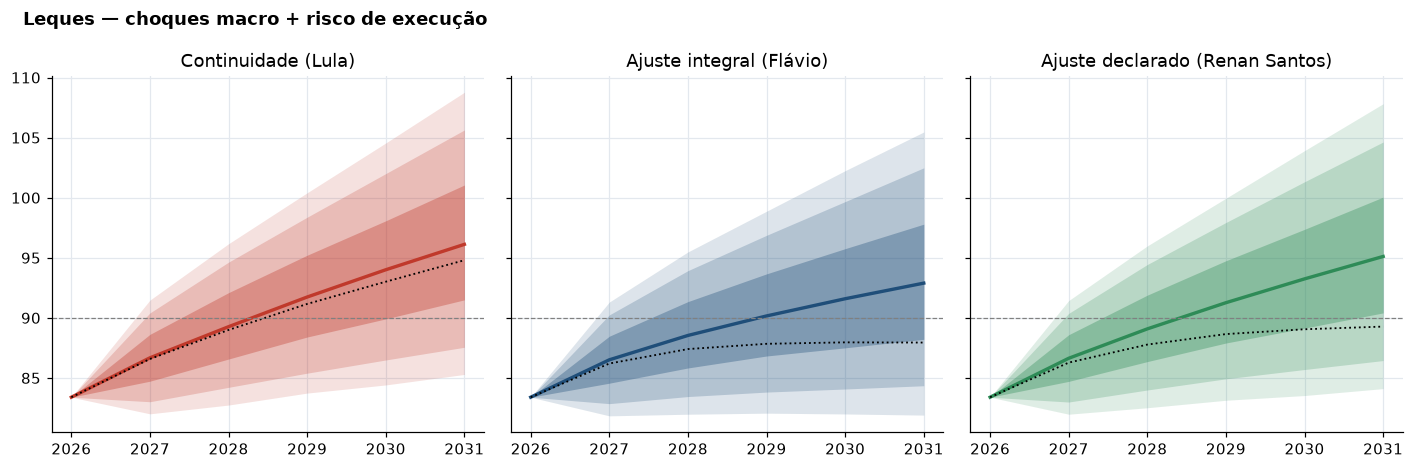

In [9]:
def leques(res, titulo):
    fig, axs = plt.subplots(1, 3, figsize=(13, 4.3), sharey=True)
    for ax, (c, cfg) in zip(axs.flat, CENARIOS.items()):
        q = np.c_[np.full(7, BASE["d0"]), np.percentile(res[c]["d"], [5, 10, 25, 50, 75, 90, 95], axis=0)]
        for (lo, hi), a in [((0, 6), .15), ((1, 5), .22), ((2, 4), .35)]:
            ax.fill_between(anos_ext, q[lo], q[hi], color=cfg["cor"], alpha=a, lw=0)
        ax.plot(anos_ext, q[3], color=cfg["cor"], lw=2.2)
        ax.plot(anos_ext, np.r_[BASE["d0"], tab[c]], color="k", ls=":", lw=1.2)
        ax.axhline(90, color="grey", ls="--", lw=.8); ax.set_title(cfg["nome"]); ax.yaxis.set_major_formatter(virg)
    fig.suptitle(titulo, x=0.02, ha="left", weight="bold"); plt.tight_layout(); plt.show()

leques(res_u1, "Leques — só choques macro (u = 1)")
leques(res_ex, "Leques — choques macro + risco de execução")

## 8. A diferença entre os favoritos sob incerteza

Com os mesmos choques, a diferença A − B1 trajetória a trajetória. O **ponto de empate** é a fração de B1 que iguala a dívida de A quando A entrega 70% do seu plano.

integral           mediana  6.90 p.p. | p5–p95  6.58 a  7.63 | P(B1 < A) = 100.0%
base               mediana  3.30 p.p. | p5–p95  0.30 a  6.14 | P(B1 < A) = 96.6%
B1 execução baixa  mediana  1.54 p.p. | p5–p95 -1.18 a  4.63 | P(B1 < A) = 80.9%
A − C (base)       mediana  0.99 p.p. | P(C < A) = 73.3%
Ponto de empate: u_B1 = 0.26; P(u_B1 < u*) sob Beta(5,5; 4,5) = 2.6%


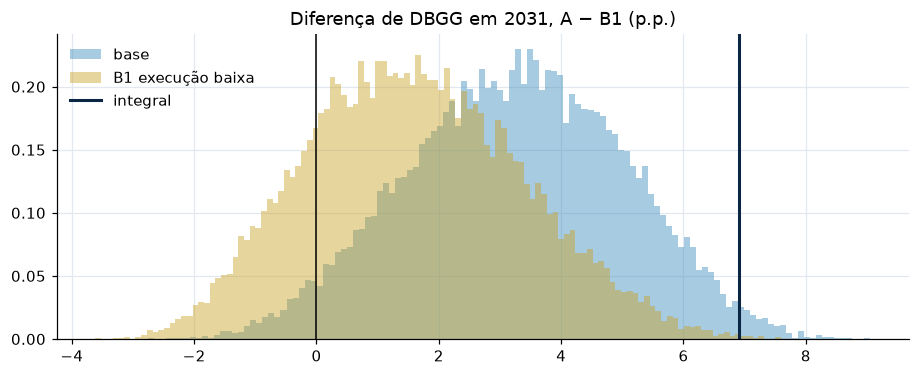

In [10]:
for lab, R in [("integral", res_u1), ("base", res_ex), ("B1 execução baixa", res_b1low)]:
    d = R["A"]["d"][:, -1] - R["B1"]["d"][:, -1]
    print(f"{lab:18s} mediana {np.median(d):5.2f} p.p. | p5–p95 {np.percentile(d, 5):5.2f} a {np.percentile(d, 95):5.2f} | P(B1 < A) = {(d > 0).mean():.1%}")
d = res_ex["A"]["d"][:, -1] - res_ex["C"]["d"][:, -1]
print(f"A − C (base)       mediana {np.median(d):5.2f} p.p. | P(C < A) = {(d > 0).mean():.1%}")

alvo = simular(CENARIOS["A"]["pb"], u=np.array([0.70]))["d"][0, -1]
us = np.linspace(0, 1, 1001)
vals = np.array([simular(CENARIOS["B1"]["pb"], u=np.array([u]))["d"][0, -1] for u in us])
u_star = us[np.argmin(np.abs(vals - alvo))]
print(f"Ponto de empate: u_B1 = {u_star:.2f}; P(u_B1 < u*) sob Beta(5,5; 4,5) = {(np.random.default_rng(1).beta(5.5, 4.5, 400000) < u_star).mean():.1%}")

fig, ax = plt.subplots(figsize=(10, 3.6))
for lab, R, cor in [("base", res_ex, "#3C8DBC"), ("B1 execução baixa", res_b1low, "#C9A227")]:
    d = R["A"]["d"][:, -1] - R["B1"]["d"][:, -1]
    ax.hist(d, bins=120, density=True, alpha=.45, color=cor, label=lab)
ax.axvline(np.median(res_u1["A"]["d"][:, -1] - res_u1["B1"]["d"][:, -1]), color="#0B2545", lw=2, label="integral")
ax.axvline(0, color="k", lw=1); ax.legend(); ax.set_title("Diferença de DBGG em 2031, A − B1 (p.p.)"); plt.show()

## 9. Mistura ponderada pela eleição (50% A; 50% B1) e decomposição da variância

p5          83.40
p25         89.80
mediana     94.50
p75         99.40
p95        107.10
prob_cai     8.80
prob_>90    74.00
prob_>95    47.20
dtype: float64

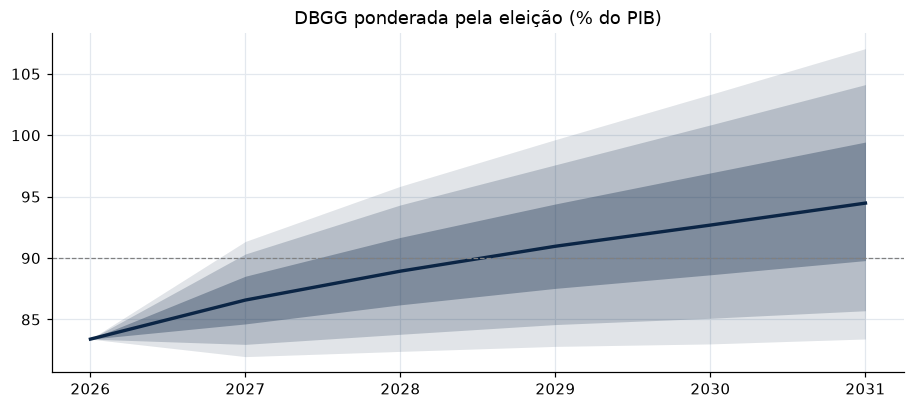

Lei da variância total (DBGG 2031): {'macro': '88.8%', 'execucao': '6.2%', 'eleicao': '4.9%'} | desvio-padrão total 7.4 p.p.
Com os choques da v1:             {'macro': '75.5%', 'execucao': '10.6%', 'eleicao': '13.9%'}


In [11]:
pesos = {"A": 0.5, "B1": 0.5}   # altere conforme sua leitura das pesquisas
mix = mistura(res_ex, pesos, N=N)
display(pd.Series(estatisticas(mix["d"])).round(1))

q = np.c_[np.full(7, BASE["d0"]), np.percentile(mix["d"], [5, 10, 25, 50, 75, 90, 95], axis=0)]
fig, ax = plt.subplots(figsize=(10, 4))
for (lo, hi), a in [((0, 6), .12), ((1, 5), .2), ((2, 4), .32)]:
    ax.fill_between(anos_ext, q[lo], q[hi], color="#0B2545", alpha=a, lw=0)
ax.plot(anos_ext, q[3], color="#0B2545", lw=2.2); ax.axhline(90, color="grey", ls="--", lw=.8)
ax.set_title("DBGG ponderada pela eleição (% do PIB)"); ax.yaxis.set_major_formatter(virg); plt.show()

dv = decompor_variancia(res_ex, res_u1, pesos)
print("Lei da variância total (DBGG 2031):", {k: f"{v:.1%}" for k, v in dv.items() if k != "total_var"},
      f"| desvio-padrão total {np.sqrt(dv['total_var']):.1f} p.p.")
r1u = monte_carlo(N, choques=CHOQUES_V1, exec_ab=INTEGRAL); r1e = monte_carlo(N, choques=CHOQUES_V1)
dv1 = decompor_variancia(r1e, r1u, pesos)
print("Com os choques da v1:            ", {k: f"{v:.1%}" for k, v in dv1.items() if k != "total_var"})

## 10. Sensibilidade

### 10.1 Parâmetros (diferença de DBGG em 2031 entre A e B1, determinístico)
Os parâmetros só atuam sobre a parte da diferença que não vem do primário direto (seção 6).

In [12]:
casos = [("mu", 0.3, 0.8, "param"), ("kappa", 0.10, 0.50, "param"), ("delta", 0.0, 0.08, "param"),
         ("lam", 0.3, 0.8, "param"), ("eps_fx", 3.0, 9.0, "param"), ("r_impl", 4.7, 5.7, "base"),
         ("g", -0.5, 0.5, "base_g"), ("d0", 82.4, 84.4, "base")]

def gap(param=None, base=None, planoB=None, planoA=None):
    a = simular(CENARIOS["A"]["pb"] if planoA is None else planoA, param=param, base=base)["d"][0, -1]
    b = simular(CENARIOS["B1"]["pb"] if planoB is None else planoB, param=param, base=base)["d"][0, -1]
    return a, b, a - b

linhas = [dict(parametro="base", valor="—", A=gap()[0], B1=gap()[1], dif=gap()[2])]
for k, lo, hi, tipo in casos:
    for val in (lo, hi):
        if tipo == "param": a, b, d = gap(param={k: val})
        elif tipo == "base_g": a, b, d = gap(base={"g": BASE["g"] + val})
        else: a, b, d = gap(base={k: val})
        linhas.append(dict(parametro=k, valor=val, A=a, B1=b, dif=d))
display(pd.DataFrame(linhas).round(2))

,parametro,valor,A,B1,dif
0,base,—,94.80,87.95,6.85
1,mu,0.30,94.71,87.70,7.00
2,mu,0.80,94.94,88.31,6.63
3,kappa,0.10,95.39,89.50,5.89
4,kappa,0.50,94.21,86.42,7.80
5,delta,0.00,95.02,88.45,6.57
6,delta,0.08,94.58,87.43,7.14
7,lam,0.30,95.05,88.59,6.47
8,lam,0.80,94.58,87.42,7.16
9,eps_fx,3.00,94.84,88.05,6.79


### 10.2 O que os programas não quantificam
Custo líquido dos cortes de tributos prometidos por Flávio (IVA, energia, combustíveis) e gasto novo não previsto em A, como redução do primário planejado (metade em 2028, integral a partir de 2029).

In [13]:
rampa = np.array([0.0, 0.5, 1.0, 1.0, 1.0])
grade = pd.DataFrame({f"A +{ca}% PIB": {f"B1 −{cb}% PIB": gap(planoB=CENARIOS["B1"]["pb"] - cb * rampa,
                                                            planoA=CENARIOS["A"]["pb"] - ca * rampa)[2]
                                        for cb in [0, 0.25, 0.5, 0.75, 1.0]} for ca in [0, 0.5, 1.0]})
display(grade.round(1))
cs = np.linspace(0, 3, 301)
g_ = np.array([gap(planoB=CENARIOS["B1"]["pb"] - c * rampa)[2] for c in cs])
print(f"Custo dos cortes de tributos que zera a diferença: {cs[np.argmin(np.abs(g_))]:.2f}% do PIB")

,A +0% PIB,A +0.5% PIB,A +1.0% PIB
B1 −0% PIB,6.90,9.10,11.30
B1 −0.25% PIB,5.80,8.00,10.20
B1 −0.5% PIB,4.70,6.90,9.10
B1 −0.75% PIB,3.60,5.80,8.00
B1 −1.0% PIB,2.50,4.70,7.00


Custo dos cortes de tributos que zera a diferença: 1.56% do PIB


## 11. O que um pregão implica

A reação diária a uma pesquisa deve ser comparada à diferença entre cenários **multiplicada** pela variação de probabilidade que a pesquisa provocou.

In [14]:
sa, sb = simular(CENARIOS["A"]["pb"]), simular(CENARIOS["B1"]["pb"])
fxgap = (sa["cambio"][0, 3] / sb["cambio"][0, 3] - 1) * 100
print(f"Diferença de câmbio A vs B1 em 2030: {fxgap:.2f}%  |  Selic: {sa['selic'][0, 3] - sb['selic'][0, 3]:.2f} p.p.")
for dp in [0.03, 0.05, 0.10]:
    print(f"Pesquisa move P(Flávio) em {dp:.0%}: o modelo explica {fxgap * dp:.2f}% no dólar; "
          f"um pregão de −0,86% implicaria diferença de {0.86 / dp:.1f}% ({0.86 / dp / fxgap:.1f}× o modelo)")
print(f"Variação de probabilidade necessária para −0,86% com a diferença do modelo: {0.86 / fxgap:.0%}")

Diferença de câmbio A vs B1 em 2030: 2.91%  |  Selic: 0.32 p.p.
Pesquisa move P(Flávio) em 3%: o modelo explica 0.09% no dólar; um pregão de −0,86% implicaria diferença de 28.7% (9.9× o modelo)
Pesquisa move P(Flávio) em 5%: o modelo explica 0.15% no dólar; um pregão de −0,86% implicaria diferença de 17.2% (5.9× o modelo)
Pesquisa move P(Flávio) em 10%: o modelo explica 0.29% no dólar; um pregão de −0,86% implicaria diferença de 8.6% (3.0× o modelo)
Variação de probabilidade necessária para −0,86% com a diferença do modelo: 30%


## 12. Calibração dos choques com os erros do Focus

Para cada ano $t$ de 2003 a 2025: realizado − mediana do Focus de meados de setembro de $t-1$ (mesmo horizonte do relatório).
O erro do juro real é medido **além da regra de Taylor** (descontadas 0,5 vez as surpresas de inflação e de PIB) e o do primário, **além do componente cíclico** (0,2 vez a surpresa de PIB), para não contar duas vezes o que o modelo já gera. 2020–21 ficam de fora (pandemia).

A tabela abaixo foi baixada do BCB em 26/09/2026 (Focus/Olinda; SGS 7326, 13522, 4189, 5793). Com `CALIBRAR = True`, ela é baixada de novo.
Colunas: `g_e`, `pi_e`, `s_e`, `s_e_prev`, `pb_e` = medianas do Focus de set/(t−1) para PIB, IPCA, Selic fim de t, Selic fim de t−1 e primário; `g`, `pi`, `s_avg`, `pb` = realizados (Selic média do ano; primário com superávit positivo).

In [15]:
CALIBRAR = False
DADOS_CALIB = {
    2003: [np.float64(3.0), np.float64(5.35), np.float64(15.0), np.float64(17.0), np.float64(3.75), np.float64(1.14), np.float64(9.3), np.float64(23.3683), np.float64(3.24)],
    2004: [np.float64(3.0), np.float64(6.1), np.float64(15.0), np.float64(17.94), np.float64(4.25), np.float64(5.76), np.float64(7.6), np.float64(16.2442), np.float64(3.69)],
    2005: [np.float64(3.5), np.float64(5.8), np.float64(15.0), np.float64(16.75), np.float64(4.25), np.float64(3.2), np.float64(5.69), np.float64(19.1242), np.float64(3.74)],
    2006: [np.float64(3.5), np.float64(4.8), np.float64(15.75), np.float64(18.0), np.float64(4.25), np.float64(3.96), np.float64(3.14), np.float64(15.2783), np.float64(3.15)],
    2007: [np.float64(3.5), np.float64(4.33), np.float64(12.5), np.float64(13.75), np.float64(4.25), np.float64(6.07), np.float64(4.46), np.float64(11.98), np.float64(3.24)],
    2008: [np.float64(4.32), np.float64(4.0), np.float64(10.25), np.float64(11.0), np.float64(3.66), np.float64(5.09), np.float64(5.9), np.float64(12.355), np.float64(3.33)],
    2009: [np.float64(3.6), np.float64(4.94), np.float64(13.79), np.float64(14.75), np.float64(3.95), np.float64(-0.13), np.float64(4.31), np.float64(10.0625), np.float64(1.94)],
    2010: [np.float64(4.2), np.float64(4.3), np.float64(9.25), np.float64(8.75), np.float64(2.5), np.float64(7.53), np.float64(5.91), np.float64(9.8025), np.float64(2.62)],
    2011: [np.float64(4.5), np.float64(4.95), np.float64(11.75), np.float64(10.75), np.float64(2.93), np.float64(3.97), np.float64(6.5), np.float64(11.665), np.float64(2.94)],
    2012: [np.float64(3.7), np.float64(5.5), np.float64(10.75), np.float64(11.0), np.float64(2.6), np.float64(1.92), np.float64(5.84), np.float64(8.5308), np.float64(2.18)],
    2013: [np.float64(4.0), np.float64(5.5), np.float64(8.25), np.float64(7.5), np.float64(2.8), np.float64(3.0), np.float64(5.91), np.float64(8.1783), np.float64(1.71)],
    2014: [np.float64(2.21), np.float64(5.96), np.float64(9.75), np.float64(9.75), np.float64(1.5), np.float64(0.5), np.float64(6.41), np.float64(10.8558), np.float64(-0.56)],
    2015: [np.float64(1.01), np.float64(6.28), np.float64(11.38), np.float64(11.0), np.float64(1.8), np.float64(-3.55), np.float64(10.67), np.float64(13.3667), np.float64(-1.86)],
    2016: [np.float64(-0.8), np.float64(5.7), np.float64(12.25), np.float64(14.25), np.float64(0.0), np.float64(-3.28), np.float64(6.29), np.float64(14.0792), np.float64(-2.48)],
    2017: [np.float64(1.36), np.float64(5.12), np.float64(11.0), np.float64(13.75), np.float64(-2.1), np.float64(1.32), np.float64(2.95), np.float64(10.0792), np.float64(-1.68)],
    2018: [np.float64(2.2), np.float64(4.1), np.float64(7.0), np.float64(7.0), np.float64(-2.21), np.float64(1.78), np.float64(3.75), np.float64(6.4833), np.float64(-1.55)],
    2019: [np.float64(2.5), np.float64(4.12), np.float64(8.0), np.float64(6.5), np.float64(-1.5), np.float64(1.22), np.float64(4.31), np.float64(5.94), np.float64(-0.84)],
    2020: [np.float64(2.0), np.float64(3.8), np.float64(5.0), np.float64(5.0), np.float64(-1.0), np.float64(-3.28), np.float64(4.52), np.float64(2.7892), np.float64(-9.24)],
    2021: [np.float64(3.5), np.float64(3.01), np.float64(2.5), np.float64(2.0), np.float64(-2.8), np.float64(4.76), np.float64(10.06), np.float64(4.4192), np.float64(0.72)],
    2022: [np.float64(1.6296), np.float64(4.1046), np.float64(8.5), np.float64(8.25), np.float64(-1.0), np.float64(3.02), np.float64(5.79), np.float64(12.4308), np.float64(1.25)],
    2023: [np.float64(0.5), np.float64(5.011), np.float64(11.25), np.float64(13.75), np.float64(-0.5), np.float64(3.24), np.float64(4.62), np.float64(13.2), np.float64(-2.28)],
    2024: [np.float64(1.5), np.float64(3.8611), np.float64(9.0), np.float64(11.75), np.float64(-0.775), np.float64(3.42), np.float64(4.83), np.float64(10.8392), np.float64(-0.4)],
    2025: [np.float64(1.9), np.float64(3.9552), np.float64(10.5), np.float64(11.25), np.float64(-0.74), np.float64(2.29), np.float64(4.26), np.float64(14.3167), np.float64(-0.43)],
}
COLS = ["g_e", "pi_e", "s_e", "s_e_prev", "pb_e", "g", "pi", "s_avg", "pb"]

def baixar_calibracao(anos=range(2003, 2026)):
    linhas = {}
    for t in anos:
        row = {}
        for ind, key, ref in [("PIB Total", "g_e", t), ("IPCA", "pi_e", t), ("Selic", "s_e", t),
                              ("Selic", "s_e_prev", t - 1), ("Resultado primário", "pb_e", t)]:
            f = focus(ind, str(ref), f"{t-1}-09-08", f"{t-1}-09-18")
            row[key] = float(f.sort_values("Data")["Mediana"].iloc[-1])
        linhas[t] = row
    d = pd.DataFrame(linhas).T
    g = baixar_sgs(7326); d["g"] = g.groupby(g.index.year).last()
    ip = baixar_sgs(13522); d["pi"] = ip[ip.index.month == 12].groupby(ip[ip.index.month == 12].index.year).last()
    s = baixar_sgs(4189); d["s_avg"] = s.groupby(s.index.year).mean()
    pb = baixar_sgs(5793); d["pb"] = -pb[pb.index.month == 12].groupby(pb[pb.index.month == 12].index.year).last()
    return d[COLS]

cal = baixar_calibracao() if CALIBRAR else pd.DataFrame(DADOS_CALIB, index=COLS).T
cal["e_g"] = cal.g - cal.g_e
cal["e_pi"] = cal.pi - cal.pi_e
rr = ((1 + cal.s_avg / 100) / (1 + cal.pi / 100) - 1) * 100
rr_e = ((1 + (cal.s_e_prev + cal.s_e) / 2 / 100) / (1 + cal.pi_e / 100) - 1) * 100
cal["e_r_res"] = (rr - rr_e) - 0.5 * cal.e_pi - 0.5 * cal.e_g
cal["e_pb_res"] = (cal.pb - cal.pb_e) - 0.2 * cal.e_g

def ar1(serie):
    x = pd.Series(serie).dropna().astype(float)
    return float(x.std(ddof=1)), float(np.corrcoef(x.values[1:], x.values[:-1])[0, 1])

for nome, excl in [("sem 2020–21", [2020, 2021]), ("sem 2020", [2020])]:
    s = cal.drop(excl)
    (sg, rg), (sr, rr_), (sp, rp) = ar1(s.e_g), ar1(s.e_r_res), ar1(s.e_pb_res)
    print(f"{nome:12s} n={len(s)} | PIB σ={sg:.2f} ρ={rg:.2f} | juro σ={sr:.2f} ρ={rr_:.2f} | "
          f"primário σ={sp:.2f} ρ={rp:.2f} | corr(g,r)={np.corrcoef(s.e_g, s.e_r_res)[0, 1]:.2f}")
print("Choques em uso:", CHOQUES)
display(cal[["e_g", "e_pi", "e_r_res", "e_pb_res"]].round(2).T)

sem 2020–21  n=21 | PIB σ=2.15 ρ=0.13 | juro σ=1.94 ρ=-0.22 | primário σ=1.15 ρ=0.26 | corr(g,r)=-0.27
sem 2020     n=22 | PIB σ=2.12 ρ=0.15 | juro σ=2.57 ρ=-0.18 | primário σ=1.39 ρ=0.45 | corr(g,r)=-0.30
Choques em uso: {'sd_g': 2.15, 'rho_g': 0.13, 'sd_r': 1.94, 'rho_r': -0.22, 'corr_gr': -0.27, 'sd_pb': 1.15, 'rho_pb': 0.26, 'sd_d0': 1.5}


,2003,2004,2005,2006,2007,2008,2009,2010,2011,2012,...,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
e_g,-1.86,2.76,-0.30,0.46,2.57,0.77,-3.73,3.33,-0.53,-1.78,...,-2.48,-0.04,-0.42,-1.28,-5.28,1.26,1.39,2.74,1.92,0.39
e_pi,3.95,1.50,-0.11,-1.66,0.13,1.90,-0.63,1.61,1.55,0.34,...,0.59,-2.17,-0.35,0.19,0.72,7.05,1.69,-0.39,0.97,0.30
e_r_res,1.72,-3.87,3.39,0.85,-2.58,-1.61,-1.20,-3.30,-1.66,-1.83,...,1.13,1.13,0.23,-0.90,-0.53,-8.54,0.64,-0.11,-1.98,2.64
e_pb_res,-0.14,-1.11,-0.45,-1.19,-1.52,-0.48,-1.26,-0.55,0.12,-0.06,...,-1.98,0.43,0.74,0.92,-7.18,3.27,1.97,-2.33,-0.01,0.23


### Notas finais
- Sementes fixas garantem reprodutibilidade; os três cenários usam os mesmos choques macro.
- Para testar outra tradução de um programa, altere `CENARIOS[...]["pb"]` (ou `AJ_B1`, `AJ_C`) e reexecute a partir da seção 5.
- Limitações: modelo anual e calibrado; sem estrutura a termo da dívida por indexador; execução no Congresso modelada apenas via `u`; o choque de primário inclui desvios de política, que em B1 e C se somam ao risco de execução.